<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/MCCB_%EA%B7%B8%EB%A3%B9_%EB%B9%84%EA%B5%90_%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MCCB 그룹 비교 실습

## 1. 실행 준비

In [ ]:
import shutil, subprocess, sys
if shutil.which("R") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "r-base"], check=True)
subprocess.run(["Rscript", "-e", "p <- c('emmeans','mvtnorm'); m <- p[!vapply(p, requireNamespace, logical(1), quietly=TRUE)]; if(length(m)) install.packages(m, repos='https://cloud.r-project.org')"], check=True)
%pip -q install rpy2
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


## 2. sample.csv 업로드

In [ ]:
from google.colab import files
from pathlib import Path
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("sample.csv 한 개만 선택하세요.")
name, content = next(iter(uploaded.items()))
if name.lower() != "sample.csv":
    raise ValueError("sample.csv를 선택하세요.")
Path("/content/sample.csv").write_bytes(content)
print("sample.csv 업로드 완료")

Saving sample.csv to sample.csv
sample.csv 업로드 완료


## 3. 데이터 확인

In [ ]:
%%R
library(emmeans)
set.seed(20261002)
d <- read.csv("/content/sample.csv", colClasses="character", na.strings=c("", "NA", "NaN"))
names(d) <- tolower(trimws(names(d)))
vars <- c("tmt","symbol","hvlt","span_s","span_l","maze","bvmt","fluency","emotion","cpt")
stopifnot(!anyDuplicated(names(d)), all(c("id","grp","age","sex",vars) %in% names(d)))
groups <- c("1","2","3","4")
d$grp <- trimws(d$grp)
d <- d[d$grp %in% groups, ]
for (v in c("age",vars)) {
  old <- trimws(d[[v]])
  old[old == ""] <- NA_character_
  d[[v]] <- suppressWarnings(as.numeric(old))
  if (any(!is.na(old) & is.na(d[[v]]))) stop(paste(v,"에 숫자가 아닌 값이 있습니다."))
  if (any(!is.finite(d[[v]]) & !is.na(d[[v]]))) stop(paste(v,"에 무한대가 있습니다."))
}
d$grp <- factor(d$grp, levels=groups)
d$sex <- factor(d$sex)
stopifnot(nlevels(d$sex) == 2)
if (anyDuplicated(d$id)) warning("중복 ID: 반복 측정 여부를 확인하세요.")
print(table(d$grp, d$sex, useNA="ifany"))
print(colSums(is.na(d[c("age","sex",vars)])))
print(tapply(d$age, d$grp, range, na.rm=TRUE))

   
     0  1
  1 58 48
  2 43 17
  3 26 28
  4 40 29
    age     sex     tmt  symbol    hvlt  span_s  span_l    maze    bvmt fluency 
      0       0       0       0       0       0       0       0       0       0 
emotion     cpt 
      0       0 
$`1`
[1] 18 53

$`2`
[1] 17 44

$`3`
[1] 18 41

$`4`
[1] 18 47



Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'


## 4. ANOVA·ANCOVA·사후검정·A′ 생성

In [ ]:
%%R
results <- list()
posthoc <- list()
overview <- list()
adjusted_data <- d
controls <- groups

for (v in vars) {
  keep <- complete.cases(d[c(v,"grp","age","sex")])
  z <- droplevels(d[keep, ])
  stopifnot(nlevels(z$grp)==length(groups), nlevels(z$sex)==2)
  m0 <- lm(reformulate("grp",v), z)
  m1 <- lm(reformulate(c("grp","age","sex"),v), z)
  stopifnot(!anyNA(coef(m1)), df.residual(m1)>0)
  a0 <- anova(m0)
  a1 <- drop1(m1,test="F")
  cat("\n==========",v,"==========\n")
  print(table(z$grp))
  print(aggregate(z[[v]],list(grp=z$grp),function(x)c(mean=mean(x),sd=sd(x))))
  cat("\nANOVA\n"); print(a0)
  cat("\nANCOVA\n"); print(a1)
  overview[[v]] <- data.frame(test=v,n=nrow(z),ANOVA_p=a0["grp","Pr(>F)"],ANCOVA_p=a1["grp","Pr(>F)"])

  means <- list(raw=emmeans(m0,~grp),
                adjusted=emmeans(m1,~grp,weights="proportional",at=list(age=mean(z$age))))
  posthoc[[v]] <- list()
  for (kind in names(means)) {
    e <- means[[kind]]
    cat("\n",kind,"평균 및 95% 신뢰구간\n")
    print(confint(e))
    posthoc[[v]][[kind]] <- list()
    for (method in c("tukey","scheffe","bonferroni")) {
      cat("\n",method,"\n")
      p <- summary(pairs(e),infer=c(TRUE,TRUE),adjust=method)
      print(p)
      posthoc[[v]][[kind]][[method]] <- as.data.frame(p)
    }
    for (control in controls) {
      cat("\nDunnett 기준:",control,"\n")
      p <- summary(contrast(e,"trt.vs.ctrl",ref=match(control,levels(z$grp))),
                   infer=c(TRUE,TRUE),adjust="mvt")
      print(p)
      posthoc[[v]][[kind]][[paste0("Dunnett_",control)]] <- as.data.frame(p)
    }
  }

  X <- model.matrix(m1)
  j <- attr(X,"assign") %in% match(c("age","sex"),attr(terms(m1),"term.labels"))
  covariate <- drop(X[,j,drop=FALSE] %*% coef(m1)[j])
  z$A_prime <- z[[v]] - covariate + mean(covariate)
  stopifnot(max(abs(as.numeric(tapply(z$A_prime,z$grp,mean)) -
                    as.data.frame(means$adjusted)$emmean)) < 1e-7)
  adjusted_data[[paste0(v,"_adjusted")]] <- NA_real_
  adjusted_data[[paste0(v,"_adjusted")]][keep] <- z$A_prime
  results[[v]] <- list(data=z,means=means,ANOVA=m0,ANCOVA=m1)
}
overview <- do.call(rbind,overview)
overview$ANOVA_Holm10 <- p.adjust(overview$ANOVA_p,"holm")
overview$ANCOVA_Holm10 <- p.adjust(overview$ANCOVA_p,"holm")
print(overview, row.names=FALSE)


========== tmt ==========

  1   2   3   4 
106  60  54  69 
  grp    x.mean      x.sd
1   1 20.518868  5.715861
2   2 27.150000 10.835949
3   3 30.907407 10.363704
4   4 32.942029 15.901243

ANOVA
Analysis of Variance Table

Response: tmt
           Df Sum Sq Mean Sq F value   Pr(>F)    
grp         3   7703 2567.78  22.013 7.52e-13 ***
Residuals 285  33244  116.65                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

ANCOVA
Single term deletions

Model:
tmt ~ grp + age + sex
       Df Sum of Sq   RSS    AIC F value    Pr(>F)    
<none>              31738 1370.0                      
grp     3    7682.9 39421 1426.6 22.8356 2.872e-13 ***
age     1     908.1 32646 1376.1  8.0971  0.004758 ** 
sex     1     774.2 32512 1374.9  6.9033  0.009073 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

 raw 평균 및 95% 신뢰구간
 grp emmean   SE  df lower.CL upper.CL
 1     20.5 1.05 285     18.5     22.6
 2     27.1 1.39 285     24.4     29.9
 3 

## 5. MANOVA·MANCOVA
10개 검사값을 함께 비교합니다. 동일한 완전 사례 표본을 사용합니다. MANCOVA의 grp 행은 age·sex를 보정한 그룹 검정입니다. Pillai를 주 결과로 봅니다. 앞의 사후검정은 검사별 후속 비교입니다.

In [ ]:
%%R
z <- droplevels(d[complete.cases(d[c(vars,"grp","age","sex")]), ])
stopifnot(nlevels(z$grp)==length(groups),nlevels(z$sex)==2)
print(table(z$grp))
Y <- as.matrix(z[vars])
fit_manova <- manova(Y ~ grp,data=z)
fit_mancova <- manova(Y ~ age + sex + grp,data=z)
cat("MANOVA\n")
print(summary(fit_manova,test="Pillai"))
cat("MANCOVA\n")
print(summary(fit_mancova,test="Pillai"))


  1   2   3   4 
106  60  54  69 
MANOVA
           Df  Pillai approx F num Df den Df    Pr(>F)    
grp         3 0.51651   5.7817     30    834 < 2.2e-16 ***
Residuals 285                                             
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
MANCOVA
           Df  Pillai approx F num Df den Df    Pr(>F)    
age         1 0.12864   4.0451     10    274 3.402e-05 ***
sex         1 0.10570   3.2384     10    274 0.0005757 ***
grp         3 0.51737   5.7518     30    828 < 2.2e-16 ***
Residuals 283                                             
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


## 6. A′ 확인과 기본 점검
보정값은 새로 관측한 점수가 아닙니다. A′로 다시 ANOVA를 하지 않고 원래 ANCOVA 모형에서 검정합니다. 그룹별 나이 기울기나 성별 효과가 다르면 공통 보정 모형의 해석을 재검토하세요. 진단 p값 하나로 모형의 적절성을 확정할 수는 없습니다.

In [ ]:
%%R
print(head(adjusted_data[c("id","grp","age","sex","tmt","tmt_adjusted")],10))
diagnostics <- lapply(vars,function(v) {
  z <- results[[v]]$data
  m <- results[[v]]$ANCOVA
  interaction <- lm(reformulate(c("grp*age","grp*sex"),v),z)
  z$deviation <- abs(z[[v]]-ave(z[[v]],z$grp,FUN=median))
  data.frame(test=v,
    residual_Shapiro_p=shapiro.test(residuals(m))$p.value,
    raw_BrownForsythe_p=anova(lm(deviation~grp,z))["grp","Pr(>F)"],
    interaction_p=anova(m,interaction)[2,"Pr(>F)"],
    max_Cook=max(cooks.distance(m)))
})
print(do.call(rbind,diagnostics),row.names=FALSE)

         id grp age sex tmt tmt_adjusted
1  21010502   1  22   0  16     18.54507
2  21020405   1  21   0  17     19.78721
3  21020408   1  23   0  15     17.30293
4  21021501   1  24   1  15     13.68154
5  21021701   1  25   0  13     14.81865
6  21021804   1  29   0  23     23.85009
7  21022501   1  20   0  15     18.02935
8  21022701   1  23   0  27     29.30293
9  21022702   1  26   1  17     15.19726
10 21022703   1  21   1  30     29.40796
    test residual_Shapiro_p raw_BrownForsythe_p interaction_p   max_Cook
     tmt       2.297579e-15        6.264837e-06    0.17408162 0.12138599
  symbol       5.931927e-01        5.309132e-01    0.28367041 0.06393618
    hvlt       1.134264e-02        2.376420e-04    0.06628422 0.03842366
  span_s       4.004146e-01        1.478891e-02    0.77750501 0.04666633
  span_l       3.142646e-01        5.045926e-01    0.44093638 0.03913938
    maze       1.773848e-05        4.892482e-06    0.76612000 0.04723797
    bvmt       6.782444e-04        3.1

## 7. 그래프 코드
함수만 정의합니다. 그래프를 직접 보고 싶을 때 마지막 셀의 `SHOW_PLOTS <- FALSE`를 `TRUE`로 바꾸세요. 원점수/보정값 각각 막대그래프와 개인별 산점도를 보여줍니다. 오차막대는 모형에서 계산한 평균의 95% 신뢰구간입니다. 파일 저장은 하지 않습니다.

In [ ]:
%%R
graph <- function(v,adjusted=FALSE,bar=FALSE) {
  z <- results[[v]]$data
  key <- if(adjusted) "adjusted" else "raw"
  e <- as.data.frame(confint(results[[v]]$means[[key]]))
  y <- if(adjusted) z$A_prime else z[[v]]
  lim <- range(c(y,e$lower.CL,e$upper.CL,if(bar) 0),finite=TRUE)
  colors <- c("#4477AA","#EE6677","#228833","#CCBB44")
  if(bar) {
    x <- barplot(e$emmean,names.arg=e$grp,ylim=lim,col=colors,
                 main=paste(v,key),xlab="Group",ylab="Mean (95% CI)")
  } else {
    x <- seq_len(nrow(e))
    set.seed(123)
    plot(jitter(as.numeric(z$grp),amount=.12),y,xaxt="n",ylim=lim,
         xlim=c(.5,length(groups)+.5),main=paste(v,key),xlab="Group",
         ylab=if(adjusted) "A-prime" else "Score",pch=16,
         col=adjustcolor(colors[as.numeric(z$grp)],alpha.f=.5))
    axis(1,at=x,labels=e$grp)
    points(x,e$emmean,pch=18,cex=1.5)
  }
  arrows(x,e$lower.CL,x,e$upper.CL,angle=90,code=3,length=.05)
}

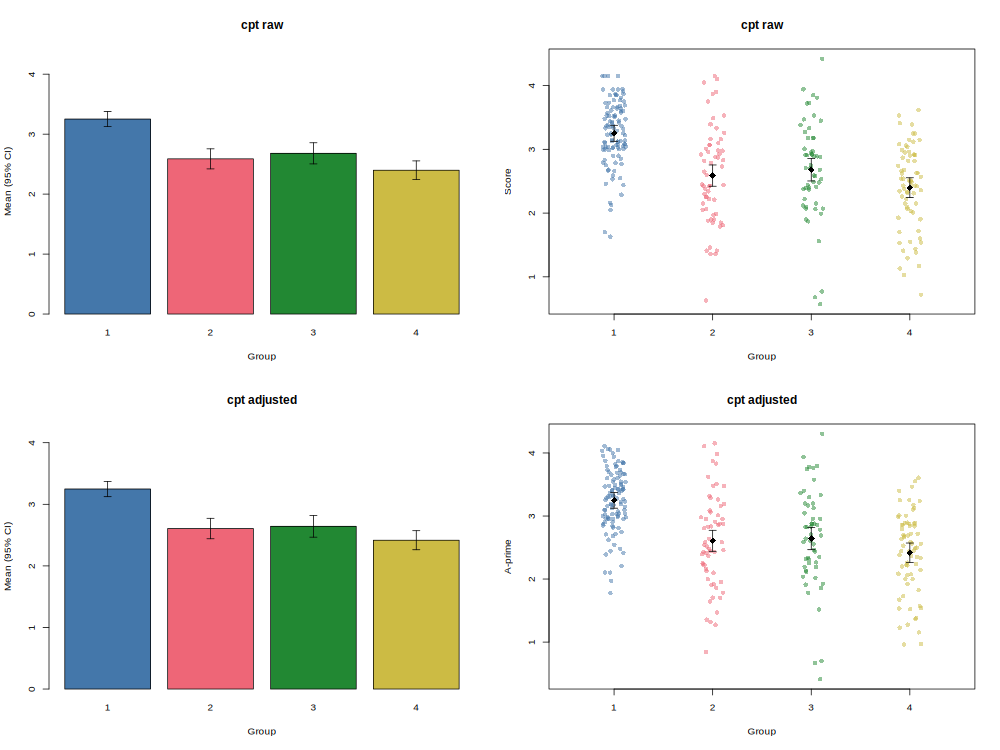

In [ ]:
%%R -w 1000 -h 750
SHOW_PLOTS <- TRUE
PLOT_VARS <- vars  # 한 검사만 보려면 "tmt"
if (SHOW_PLOTS) {
  old_par <- par(no.readonly=TRUE)
  for (v in PLOT_VARS) {
    par(mfrow=c(2,2))
    graph(v,bar=TRUE)
    graph(v)
    graph(v,adjusted=TRUE,bar=TRUE)
    graph(v,adjusted=TRUE)
  }
  par(old_par)
}